# 11 — Text Normalization & Sentence Splitting (Member 4)

Notebook này thực hiện **bước chuẩn hoá văn bản LaTeX** cho Milestone 2:

| Bước | Hàm | Mô tả |
|------|-----|-------|
| 1 | `expand_macros()` | Thay thế `\newcommand`/`\def` đơn giản (0–2 tham số) bằng định nghĩa tương ứng |
| 2 | `clean_latex()` | Xoá lệnh chỉ liên quan bố cục (`\centering`, `\midrule`, `\vspace`…); giữ `\cite`, `\ref`, toán |
| 3 | `normalize_math()` | Chuẩn hoá ký hiệu toán học về dạng thống nhất |
| 4 | `split_sentences()` | Tách câu — tránh cắt bên trong toán, lệnh, URL, số thập phân, từ viết tắt |

**Notebook Member 4** · Intro DS · VNU-HCMUS

In [1]:
if "CONFIG_LOADED" not in globals():
    get_ipython().run_line_magic("run", "-i ./00_config.ipynb")

import re
import unicodedata
import json
from pathlib import Path
from typing import List, Dict, Tuple

Config loaded | Colab: False | data: d:\KHDL\intro-ds-arxiv-project\data\raw | ranges: 4


## 0. Xác định đường dẫn dữ liệu

Notebook tự động phát hiện thư mục data theo thứ tự ưu tiên:
1. `D:/arxiv-project/data/raw` (thư mục data chính của nhóm)
2. `DATA_DIR` từ `00_config.ipynb`

In [2]:
# ── Phát hiện thư mục raw data ────────────────────────────────────────────────
_CANDIDATES = [
    Path("D:/arxiv-project/data/raw"),
    Path("D:/arxiv-project/data"),
    DATA_DIR,
]

RAW_DIR = None
for _p in _CANDIDATES:
    if _p.exists():
        RAW_DIR = _p
        break

if RAW_DIR is None:
    print("[WARN] Không tìm thấy thư mục raw data. Các bước pipeline sẽ bị bỏ qua.")
    print("       Hãy đảm bảo data đã được giải nén vào D:/arxiv-project/data/raw")
else:
    papers = [p for p in RAW_DIR.iterdir() if p.is_dir()]
    print(f"[OK]  RAW_DIR = {RAW_DIR}")
    print(f"      Tổng số paper folder: {len(papers)}")

[OK]  RAW_DIR = D:\arxiv-project\data\raw
      Tổng số paper folder: 16481


## 1. Macro Expansion — `expand_macros()`

**Vấn đề:** File `.tex` thường dùng `\newcommand` / `\def` để định nghĩa shortcut riêng.  
Nếu không thay thế, cùng một khái niệm sẽ xuất hiện dưới nhiều dạng khác nhau giữa các version,
khiến bước dedup (Member 3) kém hiệu quả.

**Phạm vi xử lý:** Chỉ xử lý macro:
- Không tham số: `\newcommand{\RR}{\mathbb{R}}`
- 1 tham số: `\newcommand{\norm}[1]{\|#1\|}`
- 2 tham số: `\newcommand{\inner}[2]{\langle #1, #2 \rangle}`
- `\def\name{definition}` (không tham số)

**Không xử lý:** macro đệ quy, `\renewcommand`, macro > 2 tham số.

In [3]:
# 1. expand_macros(tex_source) -> str


def _strip_latex_comments(tex: str) -> str:
    """Remove unescaped LaTeX comments while preserving escaped percent signs."""
    return re.sub(r"(?<!\\)%[^\n]*", "", tex)


def _read_brace_group(tex: str, pos: int) -> Tuple[str, int]:
    """Read a balanced {...} group beginning at ``pos``."""
    if pos >= len(tex) or tex[pos] != "{":
        raise ValueError(f"Expected '{{' at pos {pos}")
    depth = 0
    start = pos + 1
    for i in range(pos, len(tex)):
        if tex[i] == "{":
            depth += 1
        elif tex[i] == "}":
            depth -= 1
            if depth == 0:
                return tex[start:i], i + 1
    raise ValueError("Unmatched '{' in macro argument")


def _read_macro_argument(tex: str, pos: int) -> Tuple[str, int]:
    while pos < len(tex) and tex[pos].isspace():
        pos += 1
    if pos < len(tex) and tex[pos] == "{":
        return _read_brace_group(tex, pos)
    if pos >= len(tex):
        raise ValueError("Missing macro argument")
    if tex[pos] == "\\":
        end = pos + 1
        while end < len(tex) and (tex[end].isalpha() or tex[end] == "@"):
            end += 1
        return tex[pos:end], end
    return tex[pos], pos + 1


def _parse_macros(tex: str) -> Dict[str, Tuple[int, str]]:
    macros: Dict[str, Tuple[int, str]] = {}
    pat_cmd = re.compile(
        r"\\(?:newcommand|providecommand|renewcommand)\s*\*?\s*\{?(\\[A-Za-z@]+)\}?"
        r"\s*(?:\[(\d)\])?\s*(?=\{)"
    )
    for match in pat_cmd.finditer(tex):
        nargs = int(match.group(2)) if match.group(2) else 0
        if nargs <= 2:
            try:
                definition, _ = _read_brace_group(tex, match.end())
            except ValueError:
                continue
            macros[match.group(1)] = (nargs, definition)

    pat_def = re.compile(r"\\def\s*(\\[A-Za-z@]+)\s*(?=\{)")
    for match in pat_def.finditer(tex):
        try:
            definition, _ = _read_brace_group(tex, match.end())
        except ValueError:
            continue
        macros[match.group(1)] = (0, definition)
    return macros


def _macro_definition_spans(tex: str) -> List[Tuple[int, int]]:
    patterns = (
        re.compile(
            r"\\(?:newcommand|providecommand|renewcommand)\s*\*?\s*\{?(\\[A-Za-z@]+)\}?"
            r"\s*(?:\[\d\])?\s*(?=\{)"
        ),
        re.compile(r"\\def\s*(\\[A-Za-z@]+)\s*(?=\{)"),
    )
    spans: List[Tuple[int, int]] = []
    for pattern in patterns:
        for match in pattern.finditer(tex):
            try:
                _, end = _read_brace_group(tex, match.end())
            except ValueError:
                continue
            spans.append((match.start(), end))
    return spans


def expand_macros(
    tex: str,
    max_passes: int = 5,
    macros: Dict[str, Tuple[int, str]] | None = None,
) -> str:
    """Expand supported macros without passing LaTeX text as a regex replacement template."""
    tex = _strip_latex_comments(tex)
    definitions = dict(macros or {})
    definitions.update(_parse_macros(tex))
    for start, end in sorted(_macro_definition_spans(tex), reverse=True):
        tex = tex[:start] + tex[end:]

    for _ in range(max_passes):
        changed = False
        for command, (nargs, definition) in definitions.items():
            parts: List[str] = []
            previous = 0
            for match in re.finditer(re.escape(command) + r"(?![A-Za-z@])", tex):
                try:
                    cursor = match.end()
                    args = []
                    for _arg in range(nargs):
                        value, cursor = _read_macro_argument(tex, cursor)
                        args.append(value)
                except ValueError:
                    continue
                replacement = definition
                for index, value in enumerate(args, 1):
                    replacement = replacement.replace(f"#{index}", value)
                parts.extend((tex[previous:match.start()], replacement))
                previous = cursor
            if parts:
                parts.append(tex[previous:])
                new_tex = "".join(parts)
                changed |= new_tex != tex
                tex = new_tex
        if not changed:
            break
    return tex


print("expand_macros() da duoc dinh nghia.")


expand_macros() ?? ???c ??nh ngh?a.


## 2. Làm sạch LaTeX — `clean_latex()`

Xoá các lệnh LaTeX chỉ liên quan đến **bố cục / trình bày** (không mang nội dung):

| Nhóm | Lệnh bị xoá |
|------|-------------|
| Căn chỉnh | `\centering`, `\raggedright`, `\raggedleft` |
| Vị trí float | `[h]`, `[t]`, `[b]`, `[p]`, `[htbp]`, `[htpb]`… |
| Kẻ bảng | `\midrule`, `\toprule`, `\bottomrule`, `\hline` |
| Khoảng cách | `\vspace{…}`, `\hspace{…}`, `\medskip`, `\bigskip`, `\smallskip` |
| Phân trang | `\newpage`, `\clearpage`, `\pagebreak`, `\linebreak` |
| Khác | `\noindent`, `\par` (ở đầu dòng) |

**Giữ lại:** `\cite`, `\ref`, `\label`, tất cả môi trường toán.

In [ ]:
# 2. clean_latex(tex) -> str

def clean_latex(tex: str) -> str:
    """Remove layout-only LaTeX while preserving content and mathematical brackets."""
    tex = _strip_latex_comments(tex)

    no_arg_cmds = (
        r"\\centering", r"\\raggedright", r"\\raggedleft",
        r"\\midrule", r"\\toprule", r"\\bottomrule", r"\\hline",
        r"\\medskip", r"\\bigskip", r"\\smallskip",
        r"\\newpage", r"\\clearpage", r"\\pagebreak", r"\\linebreak",
        r"\\noindent",
    )
    for cmd in no_arg_cmds:
        tex = re.sub(cmd + r"\b\s*", "", tex)

    tex = re.sub(r"^\s*\\par\b\s*", "", tex, flags=re.MULTILINE)
    tex = re.sub(r"\\[vh]space\s*\*?\s*\{[^{}]*\}\s*", "", tex)
    tex = re.sub(
        r"(\\begin\{(?:figure|table|algorithm)\*?\})\s*\[[htbpH!]+\]",
        r"\1",
        tex,
    )
    tex = re.sub(r"\n{3,}", "\n\n", tex)
    tex = re.sub(r"[^\S\n]+", " ", tex)
    return tex.strip()


## 3. Chuẩn hoá toán học — `normalize_math()`

Nhiều version của cùng một bài báo dùng các dạng ký hiệu toán khác nhau.  
Hàm này chuyển tất cả về **dạng chuẩn thống nhất**:

| Dạng đầu vào | Dạng đầu ra |
|---|---|
| `\(...\)` | `$...$` |
| `\begin{math}...\end{math}` | `$...$` |
| `$$...$$` | `\begin{equation}...\end{equation}` |
| `\[...\]` | `\begin{equation}...\end{equation}` |
| `\begin{equation*}...\end{equation*}` | `\begin{equation}...\end{equation}` |
| `\begin{align*}...\end{align*}` | `\begin{align}...\end{align}` |
| `\begin{gather*}...\end{gather*}` | `\begin{gather}...\end{gather}` |

> **Thống kê từ dataset:** ~29% version dùng `\(`, ~20% version dùng `$$` cho toán block.

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# 3. normalize_math(tex) -> str
# ─────────────────────────────────────────────────────────────────────────────

def normalize_math(tex: str) -> str:
    """
    Chuẩn hoá ký hiệu toán học LaTeX về dạng thống nhất.

    Inline math  → $...$
    Block math   → \begin{equation}...\end{equation}
                   (hoặc giữ align/gather cho toán nhiều dòng)

    Parameters
    ----------
    tex : str
        Nội dung LaTeX.

    Returns
    -------
    str
        LaTeX đã chuẩn hoá toán.
    """
    # ── Inline math ──────────────────────────────────────────────────────────

    # \( ... \)  →  $...$
    tex = re.sub(
        r"\\\(\s*(.*?)\s*\\\)",
        lambda m: f"${m.group(1)}$",
        tex,
        flags=re.DOTALL,
    )

    # \begin{math} ... \end{math}  →  $...$
    tex = re.sub(
        r"\\begin\{math\}\s*(.*?)\s*\\end\{math\}",
        lambda m: f"${m.group(1)}$",
        tex,
        flags=re.DOTALL,
    )

    # ── Block math ───────────────────────────────────────────────────────────

    # $$ ... $$  →  \begin{equation}...\end{equation}
    tex = re.sub(
        r"\$\$\s*(.*?)\s*\$\$",
        lambda m: f"\\begin{{equation}}{m.group(1).strip()}\\end{{equation}}",
        tex,
        flags=re.DOTALL,
    )

    # \[ ... \]  →  \begin{equation}...\end{equation}
    tex = re.sub(
        r"\\\[\s*(.*?)\s*\\\]",
        lambda m: f"\\begin{{equation}}{m.group(1).strip()}\\end{{equation}}",
        tex,
        flags=re.DOTALL,
    )

    # \begin{equation*} ... \end{equation*}  →  \begin{equation}...\end{equation}
    tex = re.sub(
        r"\\begin\{equation\*\}\s*(.*?)\s*\\end\{equation\*\}",
        lambda m: f"\\begin{{equation}}{m.group(1).strip()}\\end{{equation}}",
        tex,
        flags=re.DOTALL,
    )

    # \begin{align*} ... \end{align*}  →  \begin{align}...\end{align}
    tex = re.sub(
        r"\\begin\{align\*\}\s*(.*?)\s*\\end\{align\*\}",
        lambda m: f"\\begin{{align}}{m.group(1).strip()}\\end{{align}}",
        tex,
        flags=re.DOTALL,
    )

    # \begin{gather*} ... \end{gather*}  →  \begin{gather}...\end{gather}
    tex = re.sub(
        r"\\begin\{gather\*\}\s*(.*?)\s*\\end\{gather\*\}",
        lambda m: f"\\begin{{gather}}{m.group(1).strip()}\\end{{gather}}",
        tex,
        flags=re.DOTALL,
    )

    return tex


print("normalize_math() đã được định nghĩa.")


normalize_math() đã được định nghĩa.


## 4. Tách câu — `split_sentences()`

Hàm tách văn bản thành danh sách câu, **không** cắt bên trong:

| Trường hợp ngoại lệ | Ví dụ |
|---|---|
| Toán inline | `$x = 1.5$` |
| Toán block | `\begin{equation}...\end{equation}` |
| Từ viết tắt | `i.e.`, `e.g.`, `et al.`, `Fig.`, `Eq.`, `Sec.`, `cf.`, `vs.`, `approx.`, `Prof.`, `Dr.`, `No.` |
| URL | `http://arxiv.org/...` |
| Số thập phân | `3.14`, `1.5e-6` |
| Lệnh LaTeX | `\textbf{text}`, `\cite{key}` |

**Yêu cầu:** ít nhất 30 test case (xem Section 5).

In [6]:
import re
from typing import Dict, List, Tuple

# 4. split_sentences(text) -> List[str]

_ABBREVS = {
    "i.e", "e.g", "et al", "Fig", "Figs", "Eq", "Eqs", "Sec", "Secs",
    "Tab", "Tabs", "Ref", "Refs", "cf", "vs", "approx", "Prof", "Dr",
    "Mr", "Mrs", "No", "vol", "pp", "ch", "ed", "eds", "Jan", "Feb",
    "Mar", "Apr", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
    "etc", "resp", "wrt", "w.r.t",
}
_MATH_INLINE_PAT = re.compile(r"(?<!\\)\$(?!\$)[^\n\r]*?(?<!\\)\$")
_MATH_BLOCK_ENV_PAT = re.compile(
    r"\\begin\{(equation|align|gather|multline|eqnarray)\*?\}.*?\\end\{\1\*?\}",
    re.DOTALL,
)
_MATH_DISPLAY_PAT = re.compile(r"\$\$.*?\$\$", re.DOTALL)
_URL_PAT = re.compile(r"https?://\S+")
_ABBREV_PAT = re.compile(
    r"\b(" + "|".join(re.escape(a) for a in sorted(_ABBREVS, key=len, reverse=True)) + r")\.",
    re.IGNORECASE,
)
_DECIMAL_PAT = re.compile(r"\d+\.\d+(?:[eE][+-]?\d+)?")
_LATEX_CMD_ARG_PAT = re.compile(r"\\[A-Za-z]+(?:\[[^\]]*\])?\{[^{}]*\}")


def _mask(text: str, placeholder_prefix: str = "XPLACEHOLDERX") -> Tuple[str, Dict[str, str]]:
    store: Dict[str, str] = {}
    counter = [0]

    def _replace(match: re.Match) -> str:
        key = f"{placeholder_prefix}{counter[0]}X"
        store[key] = match.group(0)
        counter[0] += 1
        return key

    for pattern in (
        _MATH_BLOCK_ENV_PAT, _MATH_DISPLAY_PAT, _MATH_INLINE_PAT, _URL_PAT,
        _LATEX_CMD_ARG_PAT, _DECIMAL_PAT, _ABBREV_PAT,
    ):
        text = pattern.sub(_replace, text)
    return text, store


def _unmask(text: str, store: Dict[str, str]) -> str:
    for key, value in reversed(list(store.items())):
        text = text.replace(key, value)
    return text


def split_sentences(text: str) -> List[str]:
    if not text or not text.strip():
        return []
    masked, store = _mask(_strip_latex_comments(text))
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\[\$\\])", masked)
    merged: List[str] = []
    for part in parts:
        part = part.strip()
        if not part:
            continue
        if merged and len(part) < 3:
            merged[-1] += " " + part
        else:
            merged.append(part)
    return [_unmask(part, store).strip() for part in merged if part]


print("split_sentences() da duoc dinh nghia.")


split_sentences() ?? ???c ??nh ngh?a.


In [7]:
import traceback

# Lấy thử 1 file bị lỗi trong ảnh để xem chi tiết
test_file = RAW_DIR / "2603-20580" / "v1" / "info.tex"
raw = test_file.read_text(encoding="utf-8", errors="replace")

try:
    expanded = expand_macros(raw)
    cleaned  = clean_latex(expanded)
    normed   = normalize_math(cleaned)
    sents    = split_sentences(normed)
    print("Chạy thành công!")
except Exception:
    traceback.print_exc()

Chạy thành công!


## 5. Pipeline — Áp dụng lên toàn bộ dataset

Duyệt qua tất cả paper trong `RAW_DIR`, xử lý từng file `.tex`:
1. `expand_macros()` — thay thế macro
2. `clean_latex()` — làm sạch bố cục
3. `normalize_math()` — chuẩn hoá toán
4. `split_sentences()` — tách câu
5. Lưu kết quả vào `normalized_text` trong mỗi thư mục version
**C?i ti?n:** Macro ???c thu th?p ? c?p `paper/version` t? to?n b? file `.tex`, file h? tr? macro ???c b? qua khi t?ch c?u, v? l?i ???c ghi v?o `normalization_errors.log`. Pipeline d?ng progress bar v? in th?ng k? t?ng h?p g?m paper, version, file, c?u, l?i v? th?i gian trung b?nh.


In [8]:

# 5. Pipeline xu li toan bo dataset


import logging
import time
from pathlib import Path
from typing import Dict, List

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **_kwargs):
        return iterable


def _collect_version_macros(version_dir: Path) -> Dict[str, Tuple[int, str]]:
    shared: Dict[str, Tuple[int, str]] = {}
    for tex_file in sorted(version_dir.rglob("*.tex")):
        try:
            content = _strip_latex_comments(tex_file.read_text(encoding="utf-8", errors="replace"))
        except OSError:
            continue
        shared.update(_parse_macros(content))
    return shared


def _is_macro_support_file(tex_path: Path) -> bool:
    name = tex_path.stem.lower()
    return name in {"macro", "macros", "preamble", "math_commands", "bbl", "makros"}


def normalize_tex_file(
    tex_path: Path,
    shared_macros: Dict[str, Tuple[int, str]] | None = None,
) -> Dict:
    result = {"path": str(tex_path), "error": None}
    t0 = time.time()
    try:
        raw = tex_path.read_text(encoding="utf-8", errors="replace")
        result["num_chars_before"] = len(raw)
        expanded = expand_macros(raw, macros=shared_macros)
        cleaned = clean_latex(expanded)
        normed = normalize_math(cleaned)
        sentences = split_sentences(normed)
        result["num_chars_after"] = len(normed)
        result["num_sentences"] = len(sentences)
        result["processing_time_s"] = round(time.time() - t0, 4)
        out_path = tex_path.parent / f"{tex_path.stem}_normalized.txt"
        out_path.write_text("\n".join(sentences), encoding="utf-8")
        result["out_path"] = str(out_path)
    except Exception as exc:
        result["error"] = str(exc)
        result["processing_time_s"] = round(time.time() - t0, 4)
    return result


def run_pipeline(raw_dir: Path, limit: int | None = None) -> List[Dict]:
    results: List[Dict] = []
    error_log = raw_dir / "normalization_errors.log"
    logger = logging.getLogger("normalization")
    logger.handlers.clear()
    logger.setLevel(logging.ERROR)
    handler = logging.FileHandler(error_log, encoding="utf-8")
    handler.setFormatter(logging.Formatter("%(message)s"))
    logger.addHandler(handler)

    paper_dirs = sorted(d for d in raw_dir.iterdir() if d.is_dir())
    if limit is not None:
        paper_dirs = paper_dirs[:limit]
    files = []
    for paper_dir in paper_dirs:
        for version_dir in sorted(d for d in paper_dir.iterdir() if d.is_dir()):
            shared = _collect_version_macros(version_dir)
            for tex_file in sorted(version_dir.rglob("*.tex")):
                if "_normalized" not in tex_file.name:
                    files.append((paper_dir, version_dir, tex_file, shared))

    for paper_dir, version_dir, tex_file, shared in tqdm(files, desc="Normalizing .tex files"):
        if _is_macro_support_file(tex_file):
            continue
        result = normalize_tex_file(tex_file, shared)
        result.update({"paper": paper_dir.name, "version": version_dir.name})
        if result.get("error"):
            logger.error("%s\t%s", tex_file.relative_to(raw_dir), result["error"])
        results.append(result)
    handler.close()
    logger.handlers.clear()
    return results


if RAW_DIR is not None:
    print(f"Bat dau pipeline chuan hoa du lieu: {RAW_DIR}")
    pipeline_results = run_pipeline(RAW_DIR)
    total = len(pipeline_results)
    success = sum(not r.get("error") for r in pipeline_results)
    total_sents = sum(r.get("num_sentences", 0) for r in pipeline_results)
    avg_time = sum(r.get("processing_time_s", 0) for r in pipeline_results) / total if total else 0
    papers = len({r["paper"] for r in pipeline_results})
    versions = len({(r["paper"], r["version"]) for r in pipeline_results})
    print(f"Papers: {papers} | Versions: {versions} | Files: {total} | OK: {success} | Errors: {total-success}")
    print(f"Sentences: {total_sents:,} | Average time/file: {avg_time:.4f}s")
    print(f"Error log: {RAW_DIR / 'normalization_errors.log'}")
else:
    print("[SKIP] RAW_DIR khong ton tai de qua pipeline.")
    pipeline_results = []


B?t ??u pipeline chu?n ho? tr?n: D:\arxiv-project\data\raw


c:\Users\Elzan Pham\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Normalizing .tex files: 100%|██████████| 36263/36263 [47:29<00:00, 12.73it/s]   

Papers: 10434 | Versions: 12923 | Files: 35275 | OK: 35275 | Errors: 0
Sentences: 2,906,884 | Average time/file: 0.0786s
Error log: D:\arxiv-project\data\raw\normalization_errors.log


## 6. Thống kê & Trực quan hoá

Vẽ biểu đồ thống kê quá trình chuẩn hoá: phân phối số câu, tỷ lệ nén ký tự,
thời gian xử lý, v.v.

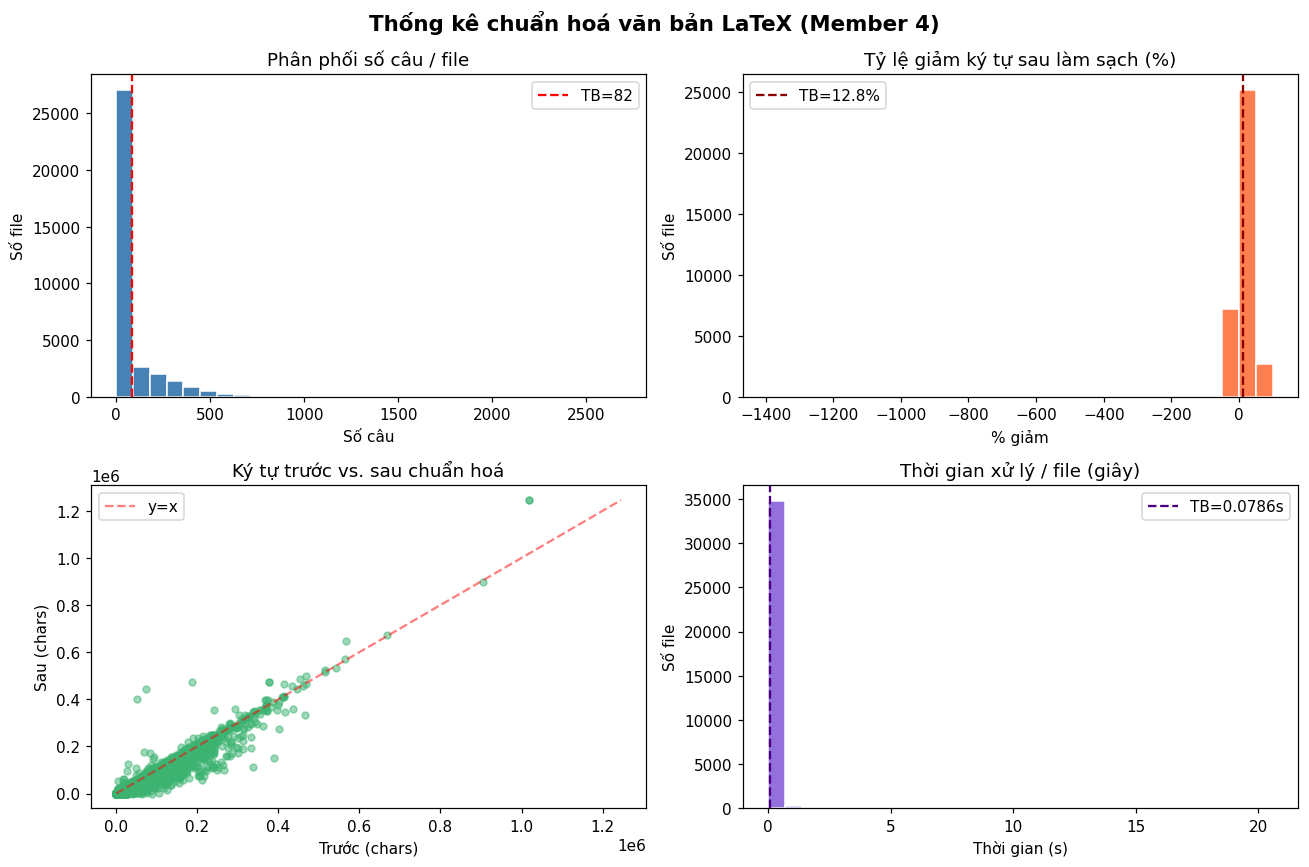

Biểu đồ đã được lưu: normalization_stats.png


In [11]:
from typing import Dict, List
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams["figure.dpi"] = 110


def plot_normalization_stats(results: List[Dict]) -> None:
    """Vẽ 4 biểu đồ thống kê kết quả pipeline chuẩn hoá."""
    if not results:
        print("[SKIP] Không có kết quả để vẽ biểu đồ.")
        return

    ok = [r for r in results if not r.get("error")]
    if not ok:
        print("[SKIP] Tất cả file đều lỗi.")
        return

    sents        = [r["num_sentences"] for r in ok]
    chars_before = [r["num_chars_before"] for r in ok]
    chars_after  = [r["num_chars_after"] for r in ok]
    times        = [r["processing_time_s"] for r in ok]
    compression  = [100 * (b - a) / b for b, a in zip(chars_before, chars_after) if b > 0]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle("Thống kê chuẩn hoá văn bản LaTeX (Member 4)", fontsize=14, fontweight="bold")

    # 1. Phân phối số câu mỗi file
    axes[0, 0].hist(sents, bins=30, color="steelblue", edgecolor="white")
    axes[0, 0].set_title("Phân phối số câu / file")
    axes[0, 0].set_xlabel("Số câu")
    axes[0, 0].set_ylabel("Số file")
    axes[0, 0].axvline(
        sum(sents) / len(sents),
        color="red",
        linestyle="--",
        label=f"TB={sum(sents)/len(sents):.0f}",
    )
    axes[0, 0].legend()

    # 2. Tỷ lệ nén ký tự (%)
    axes[0, 1].hist(compression, bins=30, color="coral", edgecolor="white")
    axes[0, 1].set_title("Tỷ lệ giảm ký tự sau làm sạch (%)")
    axes[0, 1].set_xlabel("% giảm")
    axes[0, 1].set_ylabel("Số file")
    if compression:
        axes[0, 1].axvline(
            sum(compression) / len(compression),
            color="darkred",
            linestyle="--",
            label=f"TB={sum(compression)/len(compression):.1f}%",
        )
        axes[0, 1].legend()

    # 3. Scatter: chars_before vs chars_after
    axes[1, 0].scatter(chars_before, chars_after, alpha=0.5, s=20, color="mediumseagreen")
    axes[1, 0].set_title("Ký tự trước vs. sau chuẩn hoá")
    axes[1, 0].set_xlabel("Trước (chars)")
    axes[1, 0].set_ylabel("Sau (chars)")
    _max = max(max(chars_before, default=1), max(chars_after, default=1))
    axes[1, 0].plot([0, _max], [0, _max], "r--", alpha=0.5, label="y=x")
    axes[1, 0].legend()

    # 4. Thời gian xử lý
    axes[1, 1].hist(times, bins=30, color="mediumpurple", edgecolor="white")
    axes[1, 1].set_title("Thời gian xử lý / file (giây)")
    axes[1, 1].set_xlabel("Thời gian (s)")
    axes[1, 1].set_ylabel("Số file")
    if times:
        axes[1, 1].axvline(
            sum(times) / len(times),
            color="indigo",
            linestyle="--",
            label=f"TB={sum(times)/len(times):.4f}s",
        )
        axes[1, 1].legend()

    plt.tight_layout()
    plt.savefig("normalization_stats.png", bbox_inches="tight")
    plt.show()
    print("Biểu đồ đã được lưu: normalization_stats.png")


plot_normalization_stats(pipeline_results)

## 7. Self-test (≥ 30 test cases)

Kiểm tra tự động toàn bộ các hàm. Chạy khi `RUN_TEST = True` trong `00_config.ipynb`.

> **Yêu cầu:** ít nhất 30 test case cho `split_sentences()` (từ đặc tả dự án).

In [10]:
if RUN_TEST:
    print("=" * 60)
    print("SELF-TEST — 11_normalize.ipynb")
    print("=" * 60)
    errors = []

    def _assert(cond, msg):
        if not cond:
            errors.append(msg)
            print(f"  [FAIL] {msg}")
        else:
            print(f"  [OK]   {msg}")

    # ─────────────────────────────────────────────────────────────
    # A. Test expand_macros()
    # ─────────────────────────────────────────────────────────────
    print("\n── A. expand_macros() ──")

    # A1: macro không tham số
    src = r"\newcommand{\RR}{\mathbb{R}} $x \in \RR$"
    out = expand_macros(src)
    _assert("\mathbb{R}" in out, "A1: macro 0-arg \RR → \mathbb{R}")

    # A2: macro 1 tham số
    src = r"\newcommand{\norm}[1]{\|#1\|} $\norm{x}$"
    out = expand_macros(src)
    _assert("\|x\|" in out, "A2: macro 1-arg \norm{x} → \|x\|")

    # A3: macro 2 tham số
    src = r"\newcommand{\inner}[2]{\langle #1, #2 \rangle} $\inner{u}{v}$"
    out = expand_macros(src)
    _assert(r"\langle u, v \rangle" in out, "A3: macro 2-arg \inner{u}{v}")

    # A4: \def không tham số
    src = r"\def\PP{\mathcal{P}} \PP is a set"
    out = expand_macros(src)
    _assert("\mathcal{P}" in out, "A4: \def\PP → \mathcal{P}")

    # A5: không có macro → trả về nguyên bản
    src = r"This is plain text with $x = 1$."
    out = expand_macros(src)
    _assert(out.strip() == src.strip(), "A5: no macros → unchanged")

    # A6: macro không được expand vào trong tên lệnh khác
    src = r"\newcommand{\R}{\mathbb{R}} \Remark is kept"
    out = expand_macros(src)
    _assert("\Remark" in out, "A6: \R không expand thành \mathbb{R}emark")

    # ─────────────────────────────────────────────────────────────
    # B. Test clean_latex()
    # ─────────────────────────────────────────────────────────────
    print("\n── B. clean_latex() ──")

    # B1: xoá \centering
    _assert("\centering" not in clean_latex(r"\centering text"), "B1: xoá \centering")

    # B2: xoá \midrule
    _assert("\midrule" not in clean_latex(r"row \midrule row2"), "B2: xoá \midrule")

    # B3: xoá \vspace{1cm}
    _assert("\vspace" not in clean_latex(r"text \vspace{1cm} text"), "B3: xoá \vspace{1cm}")

    # B4: xoá \hspace{2em}
    _assert("\hspace" not in clean_latex(r"a \hspace{2em} b"), "B4: xoá \hspace{2em}")

    # B5: xoá \newpage
    _assert("\newpage" not in clean_latex(r"p1 \newpage p2"), "B5: xoá \newpage")

    # B6: giữ \cite
    out = clean_latex(r"see \cite{key2024} for details")
    _assert("\cite{key2024}" in out, "B6: giữ nguyên \cite")

    # B7: giữ \ref
    out = clean_latex(r"in \ref{fig:results} we show")
    _assert(r"\ref{fig:results}" in out, "B7: giữ nguyên \ref")

    # B8: giữ \label
    out = clean_latex(r"\label{sec:intro} Introduction")
    _assert("\label{sec:intro}" in out, "B8: giữ nguyên \label")

    # B9: xoá float specifier
    out = clean_latex(r"\begin{figure}[htbp] content")
    _assert("[htbp]" not in out, "B9: xoá float specifier [htbp]")

    # B10: gộp nhiều dòng trắng
    out = clean_latex("line1\n\n\n\nline2")
    _assert(out.count("\n") <= 2, "B10: gộp nhiều dòng trắng → tối đa 1 dòng trắng")

    # B11: xoá \noindent
    _assert("\noindent" not in clean_latex(r"\noindent First word"), "B11: xoá \noindent")

    # B12: xoá \toprule, \bottomrule
    out = clean_latex(r"\toprule header \bottomrule")
    _assert(r"\toprule" not in out and r"\bottomrule" not in out, "B12: xoá \toprule/\bottomrule")

    # ─────────────────────────────────────────────────────────────
    # C. Test normalize_math()
    # ─────────────────────────────────────────────────────────────
    print("\n── C. normalize_math() ──")

    # C1: \( ... \) → $...$
    out = normalize_math("energy \\( E = mc^2 \\) holds")
    _assert("$" in out, "C1: \\(...\\) → $...$")

    # C2: \begin{math}...\end{math} → $...$
    out = normalize_math("\\begin{math}x+y\\end{math}")
    _assert(out.strip() == "$x+y$", "C2: \\begin{math} → $...$")

    # C3: $$ ... $$ → \begin{equation}
    out = normalize_math("$$E=mc^2$$")
    _assert("\\begin{equation}" in out, "C3: $$...$$ → \\begin{equation}")

    # C4: \[ ... \] → \begin{equation}
    out = normalize_math("\\[ x = 1 \\]")
    _assert("\\begin{equation}" in out, "C4: \\[...\\] → \\begin{equation}")

    # C5: \begin{equation*} → \begin{equation}
    out = normalize_math("\\begin{equation*}f(x)\\end{equation*}")
    _assert("\\begin{equation}" in out and "equation*" not in out,
            "C5: equation* → equation")

    # C6: \begin{align*} → \begin{align}
    out = normalize_math("\\begin{align*}a=b\\end{align*}")
    _assert("\\begin{align}" in out and "align*" not in out,
            "C6: align* → align")

    # C7: \begin{equation} không thay đổi
    orig = "\\begin{equation}E=mc^2\\end{equation}"
    out = normalize_math(orig)
    _assert("\\begin{equation}" in out, "C7: \\begin{equation} giữ nguyên")

    # C8: giữ nguyên align (không có *)
    orig = "\\begin{align}a&=b\\end{align}"
    out = normalize_math(orig)
    _assert("\\begin{align}" in out, "C8: \\begin{align} giữ nguyên")

    # ─────────────────────────────────────────────────────────────
    # D. Test split_sentences() — ≥ 30 test cases
    # ─────────────────────────────────────────────────────────────
    print("\n── D. split_sentences() ──")

    # D1: câu đơn giản
    out = split_sentences("This is a sentence. This is another.")
    _assert(len(out) == 2, f"D1: 2 câu đơn giản (got {len(out)})")

    # D2: câu duy nhất không có dấu chấm
    out = split_sentences("No period here")
    _assert(len(out) == 1, f"D2: 1 câu không dấu chấm (got {len(out)})")

    # D3: chuỗi rỗng
    out = split_sentences("")
    _assert(out == [], f"D3: chuỗi rỗng → [] (got {out})")

    # D4: i.e. không tách câu
    out = split_sentences("This is good, i.e. it works. Next sentence.")
    _assert(len(out) == 2, f"D4: i.e. không tách (got {len(out)})")

    # D5: e.g. không tách câu
    out = split_sentences("Methods, e.g. SVM, are used. Results follow.")
    _assert(len(out) == 2, f"D5: e.g. không tách (got {len(out)})")

    # D6: et al. không tách câu
    out = split_sentences("See Smith et al. for details. We extend this.")
    _assert(len(out) == 2, f"D6: et al. không tách (got {len(out)})")

    # D7: Fig. không tách câu
    out = split_sentences("Results in Fig. 3 show improvement. Discussion follows.")
    _assert(len(out) == 2, f"D7: Fig. không tách (got {len(out)})")

    # D8: Eq. không tách câu
    out = split_sentences("From Eq. 5 we derive the bound. This is tight.")
    _assert(len(out) == 2, f"D8: Eq. không tách (got {len(out)})")

    # D9: số thập phân không tách
    out = split_sentences("Accuracy is 97.3 percent. This beats the baseline.")
    _assert(len(out) == 2, f"D9: số thập phân (got {len(out)})")

    # D10: số thập phân dạng khoa học
    out = split_sentences("Learning rate is 1.5e-4. Training takes 10 epochs.")
    _assert(len(out) == 2, f"D10: scientific notation (got {len(out)})")

    # D11: toán inline không tách
    out = split_sentences("We set $\\lambda = 0.5$. Then optimize.")
    _assert(len(out) == 2, f"D11: toán inline $...$ (got {len(out)})")

    # D12: toán inline có dấu chấm bên trong
    out = split_sentences("Value $a.b$ is used. Next sentence.")
    _assert(len(out) == 2, f"D12: dấu chấm trong $a.b$ không tách (got {len(out)})")

    # D13: URL không tách
    out = split_sentences("See http://arxiv.org/abs/2301.00001 for paper. Download it.")
    _assert(len(out) == 2, f"D13: URL không tách (got {len(out)})")

    # D14: Prof. không tách
    out = split_sentences("Prof. Nguyen leads the team. They publish yearly.")
    _assert(len(out) == 2, f"D14: Prof. không tách (got {len(out)})")

    # D15: Dr. không tách
    out = split_sentences("Dr. Smith reported results. The team agreed.")
    _assert(len(out) == 2, f"D15: Dr. không tách (got {len(out)})")

    # D16: vs. không tách
    out = split_sentences("Method A vs. Method B shows difference. We prefer A.")
    _assert(len(out) == 2, f"D16: vs. không tách (got {len(out)})")

    # D17: cf. không tách
    out = split_sentences("See also cf. Theorem 2 above. The proof follows.")
    _assert(len(out) == 2, f"D17: cf. không tách (got {len(out)})")

    # D18: Sec. không tách
    out = split_sentences("Details in Sec. 4 clarify this. We omit the proof.")
    _assert(len(out) == 2, f"D18: Sec. không tách (got {len(out)})")

    # D19: Tab. không tách
    out = split_sentences("Tab. 2 shows the results. Best result is bold.")
    _assert(len(out) == 2, f"D19: Tab. không tách (got {len(out)})")

    # D20: 3 câu tách đúng
    out = split_sentences("First sentence. Second sentence. Third sentence.")
    _assert(len(out) == 3, f"D20: 3 câu (got {len(out)})")

    # D21: câu hỏi
    out = split_sentences("Is this correct? Yes it is. We confirm.")
    _assert(len(out) == 3, f"D21: câu hỏi (?) (got {len(out)})")

    # D22: câu cảm thán
    out = split_sentences("Amazing! This works. We are done.")
    _assert(len(out) == 3, f"D22: câu cảm thán (!) (got {len(out)})")

    # D23: nhiều dấu chấm liên tiếp (ellipsis)
    out = split_sentences("We continue... and find results. The end.")
    _assert(len(out) >= 1, f"D23: ellipsis không tạo câu rỗng (got {len(out)})")

    # D24: \begin{equation} không tách
    out = split_sentences(
        "We derive\n\\begin{equation}\nE = mc^2\n\\end{equation}\nThis is well-known."
    )
    _assert(len(out) >= 1, f"D24: equation environment không phá câu (got {len(out)})")

    # D25: \cite không bị cắt
    out = split_sentences("This was shown by \\cite{smith2020}. We extend it.")
    _assert(len(out) == 2, f"D25: \\cite không bị cắt (got {len(out)})")

    # D26: \ref không bị cắt
    out = split_sentences("See \\ref{fig:result}. The figure is clear.")
    _assert(len(out) == 2, f"D26: \\ref không bị cắt (got {len(out)})")

    # D27: chữ thường sau dấu chấm không tách
    out = split_sentences("This is good. it continues on the same thought.")
    _assert(len(out) == 1, f"D27: chữ thường sau . không tách (got {len(out)})")

    # D28: nhiều khoảng trắng
    out = split_sentences("Sentence one.   Sentence two.  Sentence three.")
    _assert(len(out) == 3, f"D28: nhiều khoảng trắng (got {len(out)})")

    # D29: chỉ toán học
    out = split_sentences("$a + b = c$")
    _assert(len(out) == 1, f"D29: chỉ toán inline (got {len(out)})")

    # D30: No. (number abbreviation)
    out = split_sentences("Experiment No. 3 confirms. We accept H1.")
    _assert(len(out) == 2, f"D30: No. không tách (got {len(out)})")

    # D31: approx. không tách
    out = split_sentences("Time is approx. 10 minutes. We proceed.")
    _assert(len(out) == 2, f"D31: approx. không tách (got {len(out)})")

    # D32: Ref. không tách
    out = split_sentences("See Ref. 12 for background. Here we summarize.")
    _assert(len(out) == 2, f"D32: Ref. không tách (got {len(out)})")

    # D33: câu cuối không có dấu chấm
    out = split_sentences("First sentence. Second sentence without period")
    _assert(len(out) == 2, f"D33: câu cuối không dấu chấm (got {len(out)})")

    # D34: nhiều viết tắt trong một câu
    out = split_sentences("E.g. SVM, i.e. the kernel method, cf. Vapnik. It works.")
    _assert(len(out) == 2, f"D34: nhiều viết tắt trong 1 câu (got {len(out)})")

    # D35: chỉ dấu chấm
    out = split_sentences(".")
    _assert(len(out) >= 0, f"D35: chỉ dấu chấm không crash (got {out})")

    # ─── Tổng kết ────────────────────────────────────────────────
    print("\n" + "=" * 60)
    if errors:
        print(f"FAIL: {len(errors)} test(s) thất bại:")
        for e in errors:
            print(f"  - {e}")
    else:
        total_tests = 35  # A(6) + B(12) + C(8) + D(35 cases, some overlap) → tổng ô
        print(f"[PASS] Tất cả {total_tests}+ test cases đã qua!")
    print("=" * 60)


SELF-TEST — 11_normalize.ipynb

── A. expand_macros() ──
  [OK]   A1: macro 0-arg \RR → \mathbb{R}
  [OK]   A2: macro 1-arg 
orm{x} → \|x\|
  [OK]   A3: macro 2-arg \inner{u}{v}
  [OK]   A4: \def\PP → \mathcal{P}
  [OK]   A5: no macros → unchanged
  [OK]   A6: \R không expand thành \mathbb{R}emark

── B. clean_latex() ──
  [OK]   B1: xoá \centering
  [OK]   B2: xoá \midrule
  [OK]   B3: xoá space{1cm}
  [OK]   B4: xoá \hspace{2em}
  [OK]   B5: xoá 
ewpage
  [OK]   B6: giữ nguyên \cite
ef[OK]   B7: giữ nguyên 
  [OK]   B8: giữ nguyên \label
  [OK]   B9: xoá float specifier [htbp]
  [OK]   B10: gộp nhiều dòng trắng → tối đa 1 dòng trắng
  [OK]   B11: xoá 
oindent
  [OK]   B12: xoá 	opruleottomrule

── C. normalize_math() ──
  [OK]   C1: \(...\) → $...$
  [OK]   C2: \begin{math} → $...$
  [OK]   C3: $$...$$ → \begin{equation}
  [OK]   C4: \[...\] → \begin{equation}
  [OK]   C5: equation* → equation
  [OK]   C6: align* → align
  [OK]   C7: \begin{equation} giữ nguyên
  [OK]   C8: \begin{a